# Cvičenie I - Úvod a časové rady I

## 1. Načítanie datasetu a knižníc

Pracujeme s datasetom, v ktorom sú pozorovania zaznamenávané v pravidelných časových intervaloch, teda s rovnakým časovým odstupom.

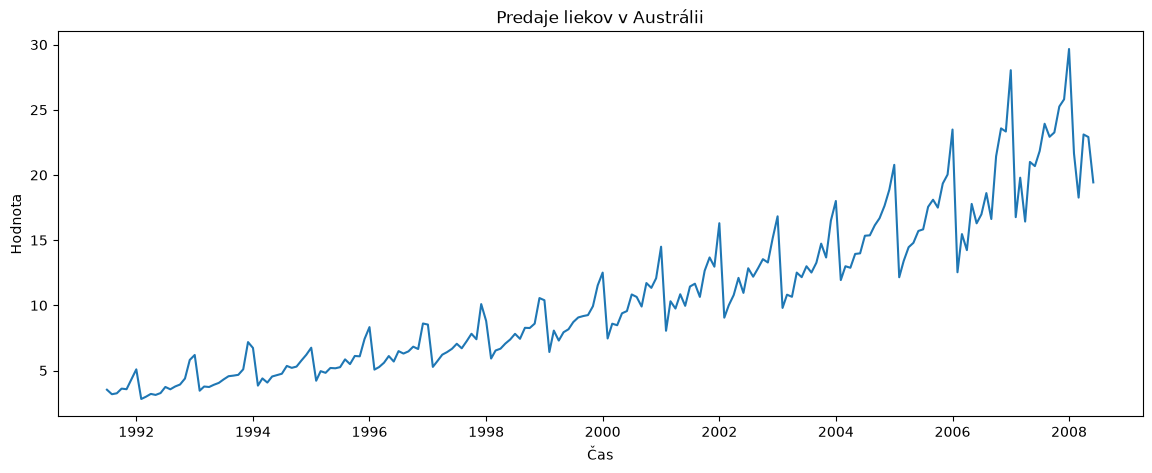

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

data_a10 = pd.read_csv(
    "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv",
    parse_dates=["date"],
    index_col="date"
)

plt.figure(figsize=(14, 5))
plt.plot(data_a10)
plt.xlabel("Čas")
plt.ylabel("Hodnota")
plt.title("Predaje liekov v Austrálii")

plt.show()

### Akú frekvenciu má tento dataset?

Frekvencia určuje význam lagu aj sezónnej periódy.

In [4]:
# TODO: Použite funkciu z knižnice pandas na zistenie frekvencie datasetu.
frequency = pd.infer_freq(data_a10.index)
print(frequency)

MS


## 2. Agregácia časového Radu

Agregáciou vieme sumarizovať a transformovať dáta cez špecifické intervaly: hodinová, denná, mesačná, kĺzavý priemer. 

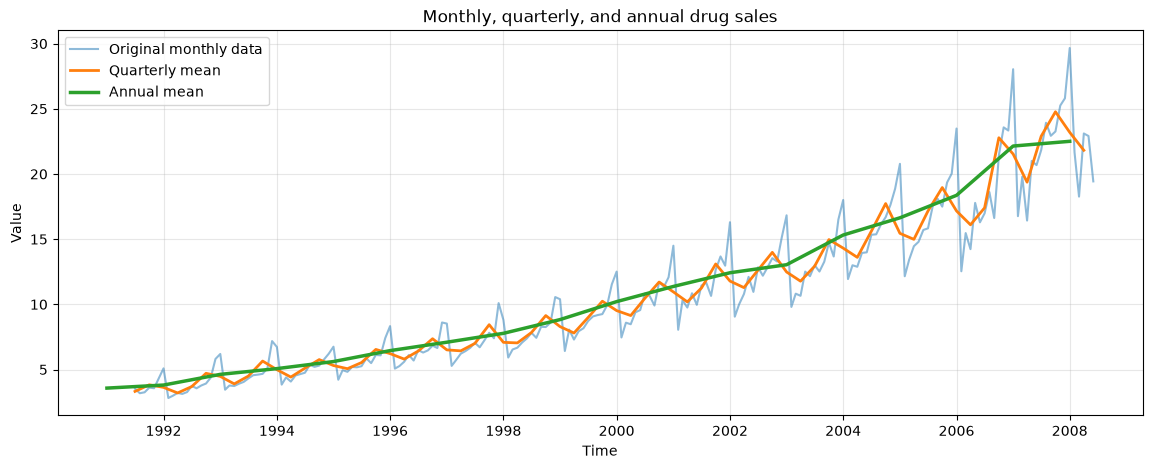

                    Monthly  Quarterly  Annual
Variance             35.486     33.419  37.081
Standard deviation    5.957      5.781   6.089


In [6]:
# TODO: Vykreslite pôvodné dáta spolu s štvrťročne a ročne agregovanými. 

# Original monthly data
monthly = data_a10["value"].sort_index()

# Quarterly and annual aggregation using mean values
quarterly = monthly.resample("QS").mean()
annual = monthly.resample("YS").mean()

# Plot all three time series
plt.figure(figsize=(14, 5))
plt.plot(monthly, label="Original monthly data", alpha=0.5)
plt.plot(quarterly, label="Quarterly mean", linewidth=2)
plt.plot(annual, label="Annual mean", linewidth=2.5)

plt.xlabel("Time")
plt.ylabel("Value")
plt.title("Monthly, quarterly, and annual drug sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Ako agregácia ovplyvnila extrémy a sezónne výkyvy? 
# TODO: Vypočítajte variabilitu pre všetky tri krivky

variability = pd.DataFrame({
    "Monthly": monthly.agg(["var", "std"]),
    "Quarterly": quarterly.agg(["var", "std"]),
    "Annual": annual.agg(["var", "std"]),
}).rename(index={
    "var": "Variance",
    "std": "Standard deviation",
})

print(variability.round(3))


## 3. Trend a sezónnosť

Trend pozorujeme vtedy, keď časový rad vykazuje dlhodobý rast alebo pokles. Sezónnosť pozorujeme vtedy, keď sa v časovom rade opakuje určitý vzor v pravidelných časových intervaloch. Časové rady môžu trend alebo sezónnosť, alebo oboje.

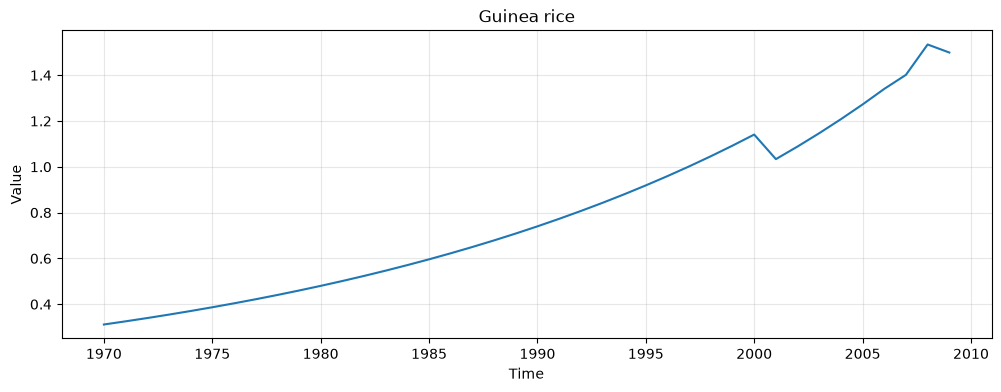

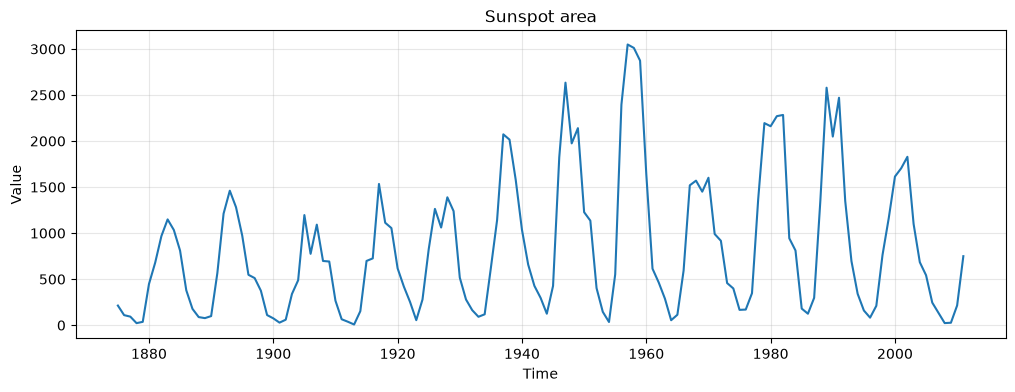

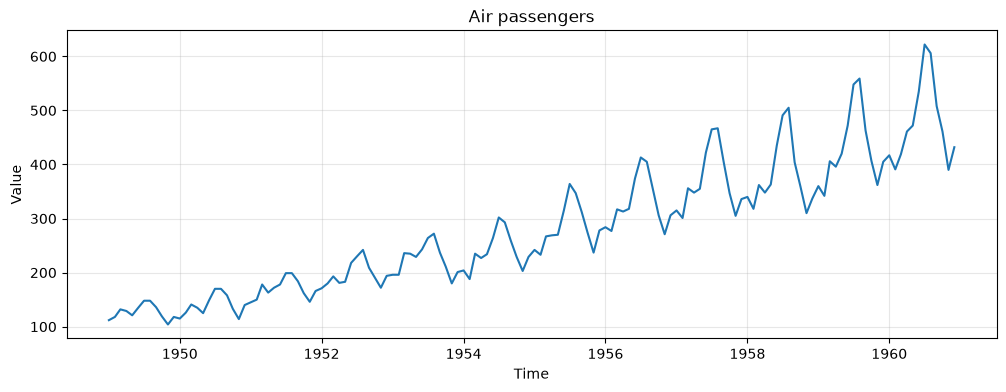

In [8]:
# TODO: Vykreslite nasledujúce datasety a určite či obsahuje trend, sezónnosť alebo obe zložky

import pandas as pd
import matplotlib.pyplot as plt

def plot_dataset(url, title):
    data = pd.read_csv(
        url,
        parse_dates=["date"],
        index_col="date"
    ).sort_index()

    plt.figure(figsize=(12, 4))
    plt.plot(data["value"])
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.grid(alpha=0.3)
    plt.show()

    return data


base_url = "https://raw.githubusercontent.com/selva86/datasets/master/"

rice = plot_dataset(base_url + "guinearice.csv", "Guinea rice")
sunspots = plot_dataset(base_url + "sunspotarea.csv", "Sunspot area")
passengers = plot_dataset(base_url + "AirPassengers.csv", "Air passengers")

## 4. Aditívna a multiplikatívna sezónnosť

Závisiac od datasetu, dáta môžeme modelovať pomocou aditívneho a multiplikatívneho. modelu. Aditívna dekompozícia predpokladá, že sezónne výkyvy majú približne konštantnú absolútnu amplitúdu. Multiplikatívna dekompozícia sa používa, keď sezónne výkyvy rastú spolu s úrovňou dát. 

Original CO2 frequency: W-SAT
Missing weekly CO2 observations: 59
An annual cycle is approximately 52 weekly observations.
Missing CO2 months before interpolation: 5
Monthly frequencies: MS MS
Seasonal period for both monthly series: 12


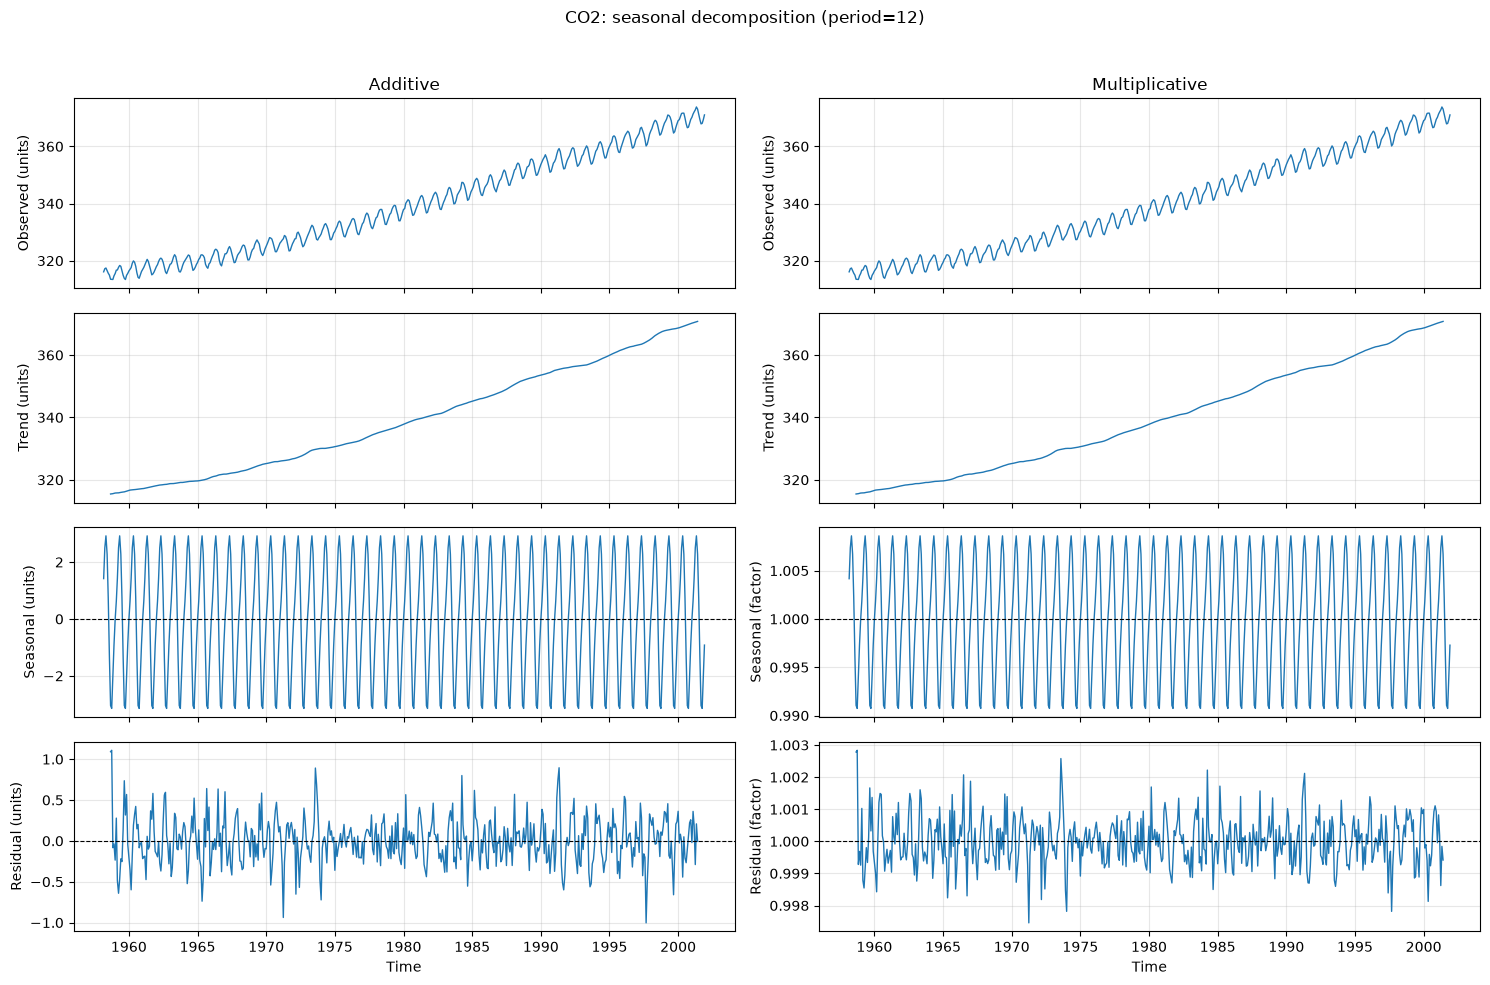

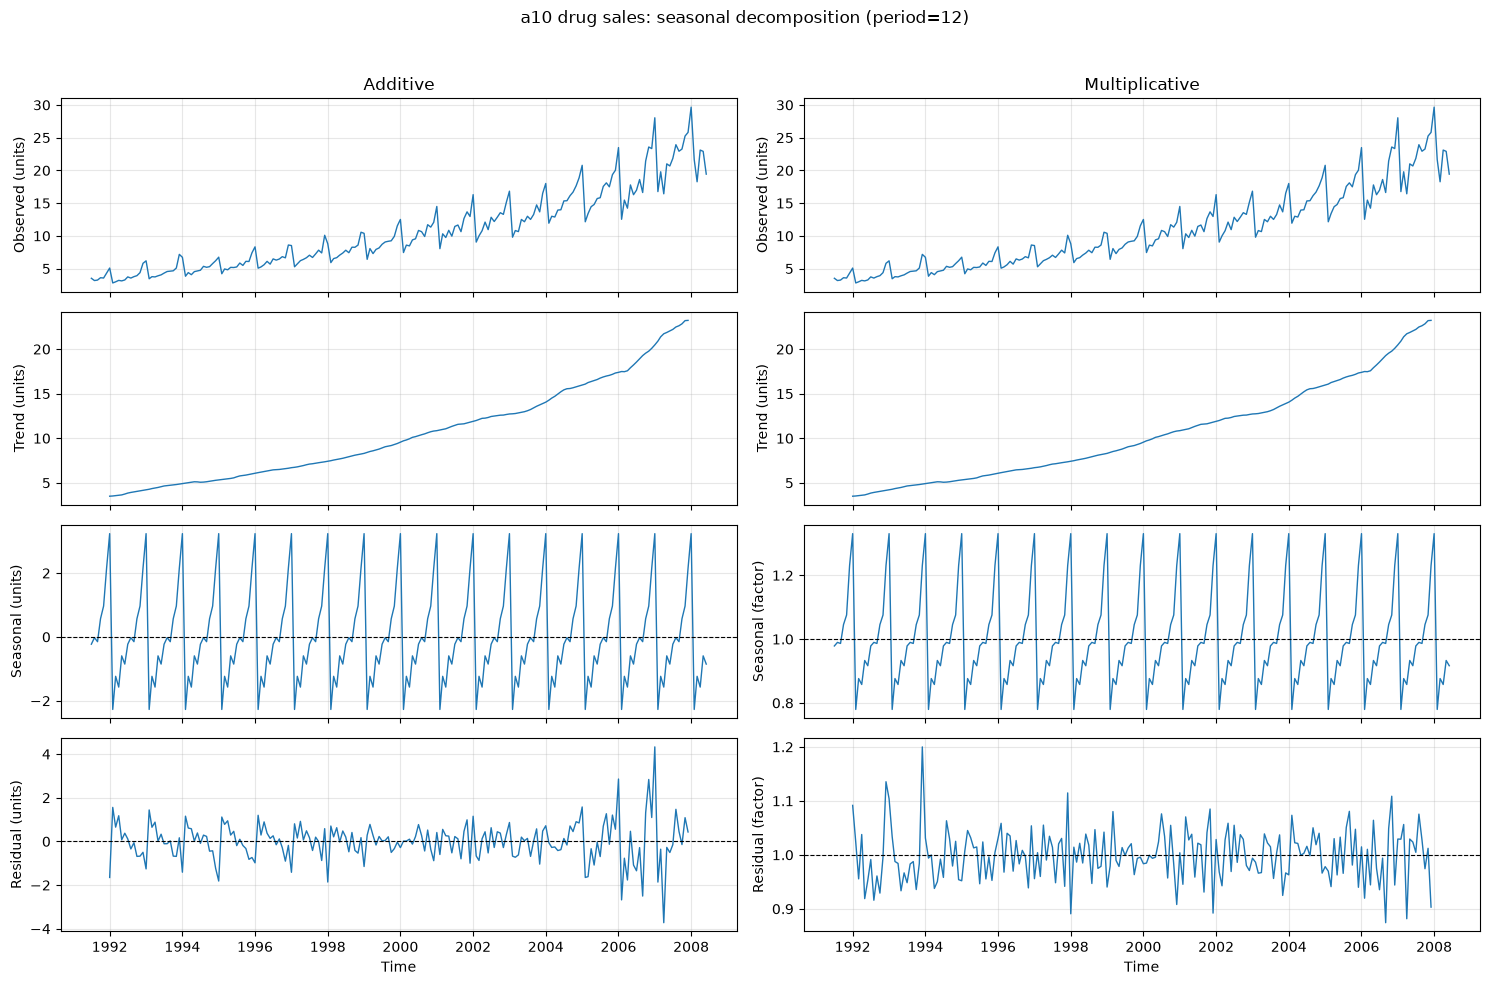

In [10]:
# TODO: Vykonajte aditívny a multiplikatívny model na datasete CO2 a datasete a10. 
# Porovnajte výsledky na grafe.

""" 
Graf by mal obsahovať 4 zložky: pozorovaný rad, trend, sezónnu zložku, rezídium.
Nezabudnite skontrolovať lag CO2 radu.
"""

import matplotlib.pyplot as plt
from statsmodels.datasets import co2
from statsmodels.tsa.seasonal import seasonal_decompose

import pandas as pd

# Inspect the original weekly frequency before choosing the seasonal period.
co2_weekly = co2.load_pandas().data["co2"].sort_index()
print("Original CO2 frequency:", pd.infer_freq(co2_weekly.index))
print("Missing weekly CO2 observations:", co2_weekly.isna().sum())
print("An annual cycle is approximately 52 weekly observations.")

# Use monthly means so both datasets have 12 observations per annual cycle.
# Interpolate missing monthly values without removing dates from the index.
co2_monthly = co2_weekly.resample("MS").mean()
print("Missing CO2 months before interpolation:", co2_monthly.isna().sum())
data_co2 = co2_monthly.interpolate(method="time", limit_area="inside")
a10_monthly = data_a10["value"].sort_index().asfreq("MS")
print("Monthly frequencies:", pd.infer_freq(data_co2.index),
      pd.infer_freq(a10_monthly.index))
print("Seasonal period for both monthly series: 12")


def compare_decomposition(series, title, period=12):
    if series.isna().any():
        raise ValueError("Handle missing values before decomposition.")
    if (series <= 0).any():
        raise ValueError("Multiplicative decomposition requires positive values.")

    results = {}
    fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex=True)

    for column, model in enumerate(("additive", "multiplicative")):
        result = seasonal_decompose(series, model=model, period=period)
        results[model] = result
        components = (result.observed, result.trend, result.seasonal, result.resid)
        labels = ("Observed", "Trend", "Seasonal", "Residual")

        for row, (component, label) in enumerate(zip(components, labels)):
            ax = axes[row, column]
            ax.plot(component.index, component.values, linewidth=1)
            is_factor = model == "multiplicative" and row >= 2
            ax.set_ylabel(label + (" (factor)" if is_factor else " (units)"))
            ax.grid(alpha=0.3)
            if row >= 2:
                ax.axhline(1 if is_factor else 0, color="black",
                           linestyle="--", linewidth=0.8)

        axes[0, column].set_title(model.capitalize())
        axes[-1, column].set_xlabel("Time")

    fig.suptitle(f"{title}: seasonal decomposition (period={period})")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    return results


co2_decomposition = compare_decomposition(data_co2, "CO2")
a10_decomposition = compare_decomposition(a10_monthly, "a10 drug sales")


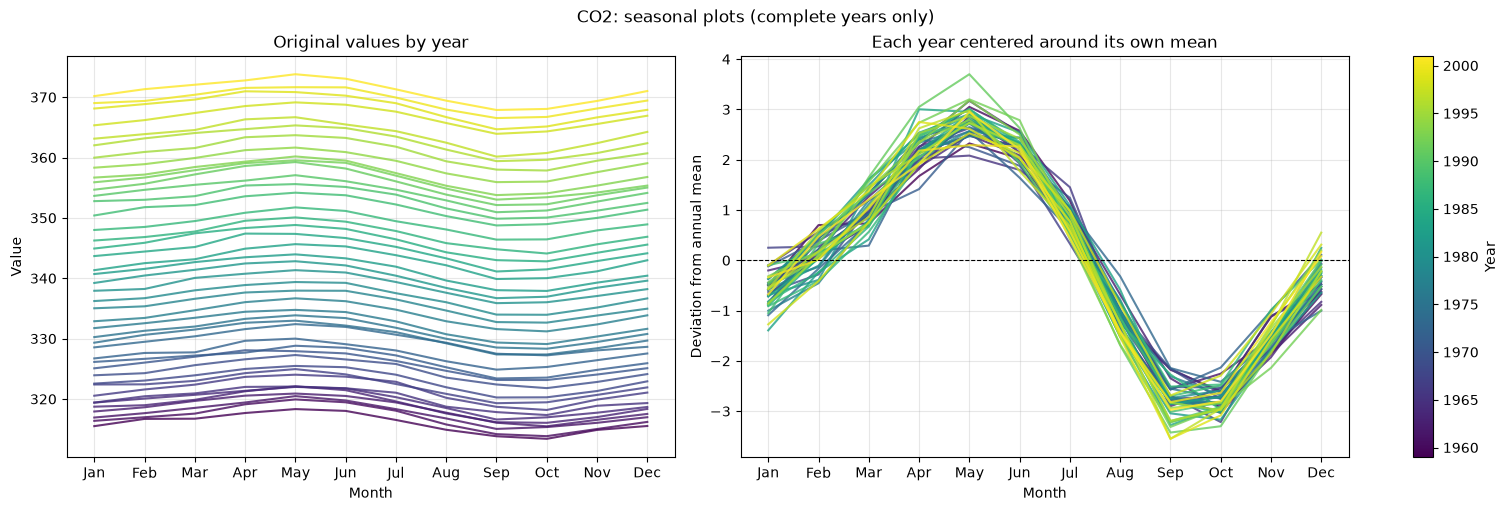

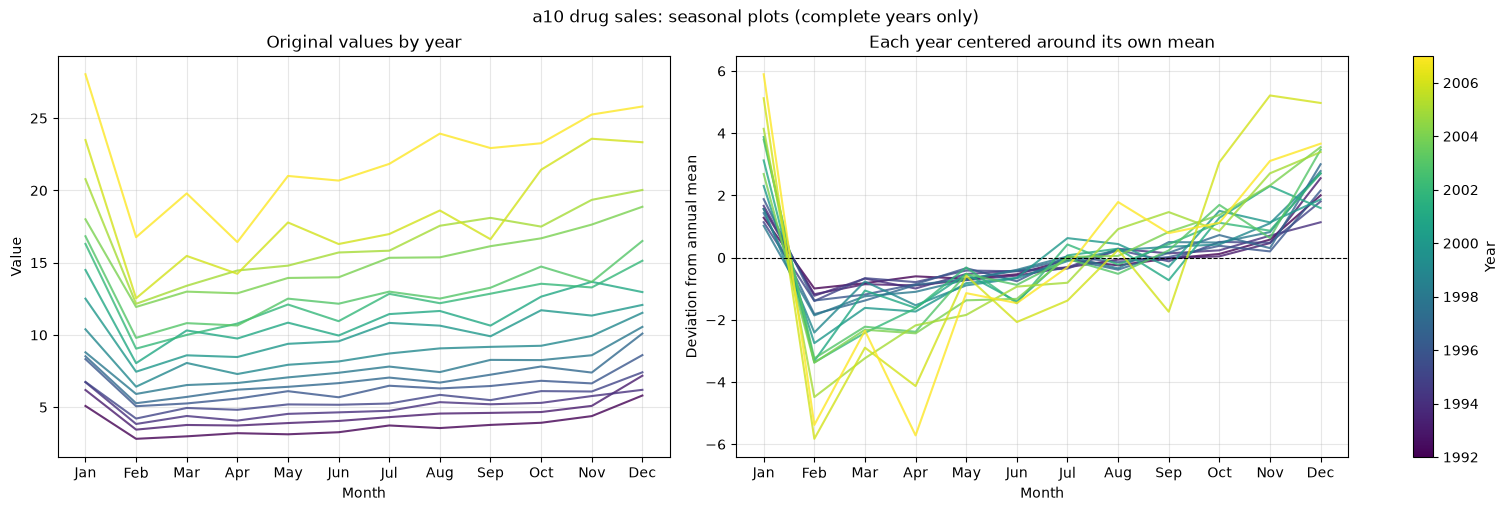

In [11]:
# TODO: Vytvorte sezónny graf CO2 a a10. 
# Je amplitúda sezónnych výkyvov približne konštantná alebo rastie?

from calendar import month_abbr
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


def plot_seasonal(series, title):
    frame = pd.DataFrame({
        "Year": series.index.year,
        "Month": series.index.month,
        "Value": series.to_numpy(),
    })
    # Exclude incomplete years so each line contains all 12 months.
    seasonal = frame.pivot(index="Month", columns="Year", values="Value")
    seasonal = seasonal.reindex(range(1, 13)).dropna(axis=1)
    centered = seasonal - seasonal.mean(axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
    norm = Normalize(vmin=seasonal.columns.min(), vmax=seasonal.columns.max())
    cmap = plt.get_cmap("viridis")

    for year in seasonal.columns:
        color = cmap(norm(year))
        axes[0].plot(seasonal.index, seasonal[year], color=color, alpha=0.8)
        axes[1].plot(centered.index, centered[year], color=color, alpha=0.8)

    axes[0].set_title("Original values by year")
    axes[0].set_ylabel("Value")
    axes[1].set_title("Each year centered around its own mean")
    axes[1].set_ylabel("Deviation from annual mean")
    axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
    for ax in axes:
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(list(month_abbr)[1:])
        ax.set_xlabel("Month")
        ax.grid(alpha=0.3)

    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes, label="Year")
    fig.suptitle(f"{title}: seasonal plots (complete years only)")
    plt.show()


plot_seasonal(data_co2, "CO2")
plot_seasonal(a10_monthly, "a10 drug sales")


### Exercise 4 — interpretation

- **CO2:** The series has an increasing trend and an annual seasonal pattern. Absolute seasonal fluctuations are relatively stable compared with the growing level, although their amplitude changes somewhat over time. An additive model is a reasonable approximation.
- **a10:** The series has an increasing trend, and seasonal fluctuations become larger as the level increases. A multiplicative model better represents this relationship than a fixed additive seasonal effect.
- Additive seasonal components and residuals are expressed in the original units and centered around zero. Multiplicative components are dimensionless factors centered around one. Their raw residual variances should not be compared directly.
- The seasonal plots show one line per complete calendar year. Centering each year removes differences in annual levels and makes changes in absolute amplitude easier to see; it does not remove the trend within each year.
- CO2 was aggregated from weekly to monthly means; missing monthly values were interpolated in time. Both decompositions use a 12-month seasonal period. Missing trend and residual values at the endpoints are expected with the default centered moving average.


## 5. Stacionarita

 Stacionárny časový rad je taký, ktorého priemer, rozptyl a autokorelácia zostávajú v čase konštantné.
 Predikcie so stacionárnymi radmi sú spoľahlivejšie. 

 Diferencia je jeden zo spôsobov ako zmeniť nestacionárny rad na stacionárny. Ak Y_t je hodnota v čase t, tak prvá diferencia sa vypočíta ako Y_t - Y_t-1. Každá diferencia odoberá informáciu. 


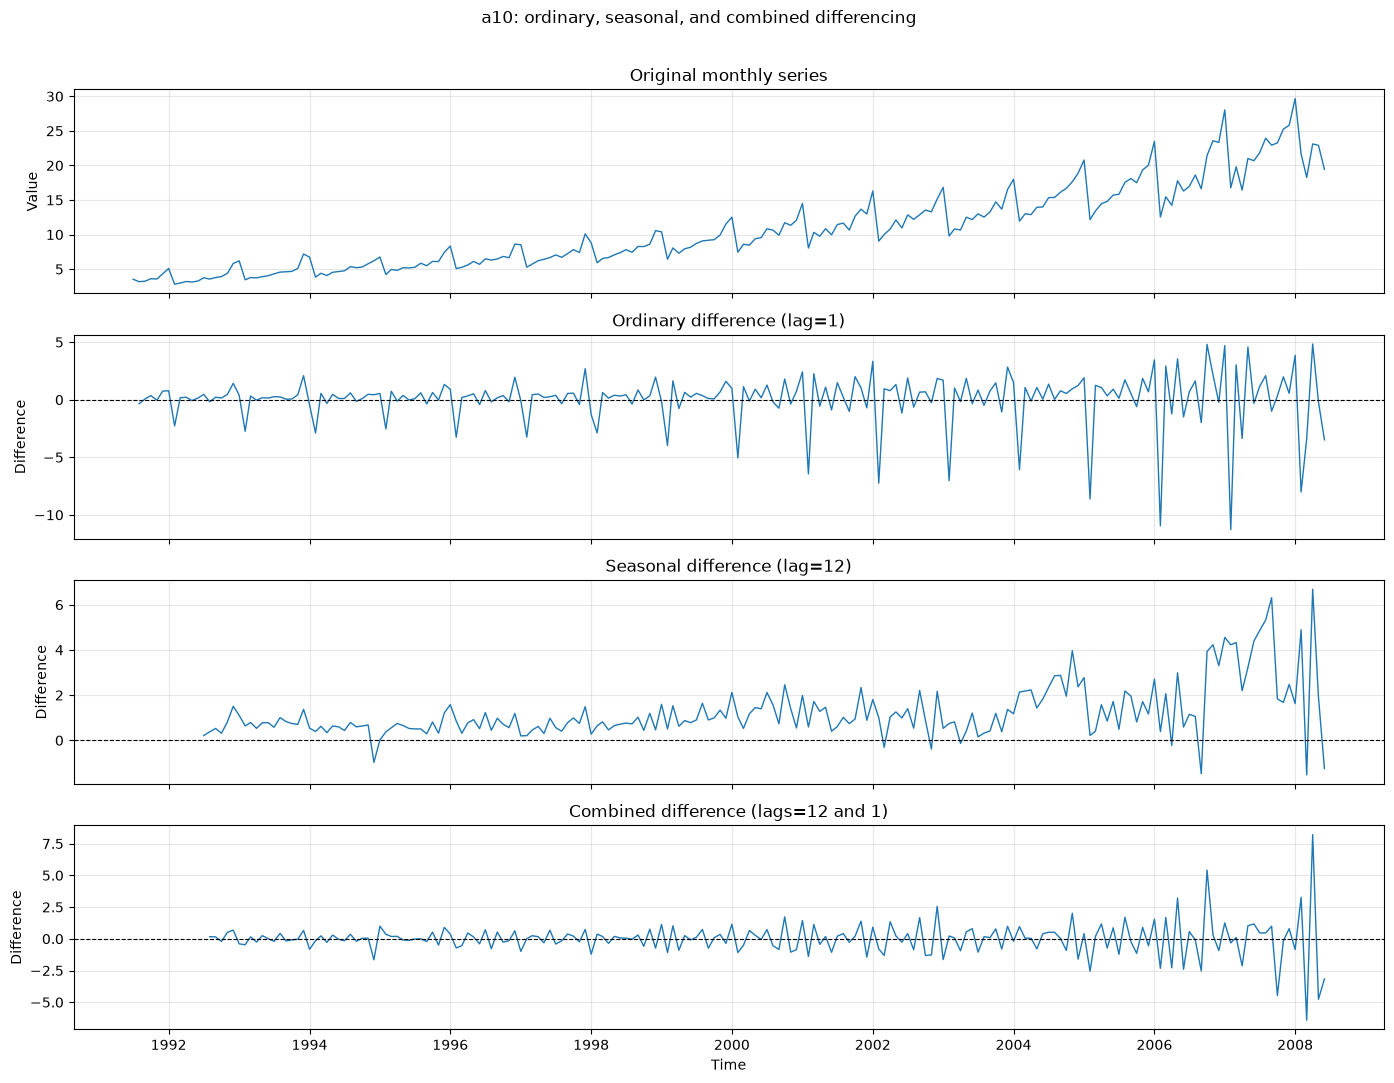

In [12]:
# TODO: Vykreslite obyčajnú diferenciu, sezónnu diferenciu a kombináciu oboch na datasete a10. 
# Porovnajte výsledky na grafoch. Ktorá diferencia odstránila trend a ktorá sezónnosť?

import matplotlib.pyplot as plt

# Keep a regular monthly index: a lag of 12 represents one year.
a10_original = data_a10["value"].sort_index().asfreq("MS")
if a10_original.isna().any():
    raise ValueError("Handle missing monthly values before differencing.")

# Ordinary difference: change from the previous month, y[t] - y[t-1].
a10_diff = a10_original.diff(1)

# Seasonal difference: change from the same month last year, y[t] - y[t-12].
a10_seasonal_diff = a10_original.diff(12)

# Combined difference: ordinary difference of the seasonal difference.
# y[t] - y[t-1] - y[t-12] + y[t-13]
a10_combined_diff = a10_seasonal_diff.diff(1)

series_to_plot = (a10_original, a10_diff, a10_seasonal_diff, a10_combined_diff)
titles = (
    "Original monthly series",
    "Ordinary difference (lag=1)",
    "Seasonal difference (lag=12)",
    "Combined difference (lags=12 and 1)",
)

fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for row, (ax, series, title) in enumerate(zip(axes, series_to_plot, titles)):
    # Drop only the undefined values introduced by differencing for plotting.
    valid = series.dropna()
    ax.plot(valid.index, valid.values, linewidth=1)
    ax.set_title(title)
    ax.set_ylabel("Value" if row == 0 else "Difference")
    ax.grid(alpha=0.3)
    if row > 0:
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

axes[-1].set_xlabel("Time")
fig.suptitle("a10: ordinary, seasonal, and combined differencing")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


### Exercise 5 — interpretation

- **Ordinary differencing (lag 1)** reduces the trend by replacing levels with month-to-month changes. It does not remove the annual seasonal pattern.
- **Seasonal differencing (lag 12)** compares each month with the same month in the previous year. It reduces the annual seasonal pattern, but a changing year-to-year growth rate can leave a trend.
- **Combined differencing** targets both the remaining trend and annual seasonality. It is a candidate transformation for this series, rather than proof of stationarity.
- Since a10 has increasing seasonal amplitude, seasonal effects may remain after differencing, and the variance may still change over time. A log or Box-Cox transformation can help stabilize the variance; this differs from removing trend and seasonality.
- The first 1, 12, and 13 values are undefined after ordinary, seasonal, and combined differencing, respectively. These values are omitted from the plots, not filled with zeros. Check the transformed series with stationarity tests in exercise 6.


## 6. Testovanie stacionarity

Ak si nie sme istí vizuálnym odhadom, použijeme ADF (Augmented Dickey-Fuller) test alebo KPSS (Kwiatkowski-Phillips-Schmidt-Shin) test. 

ADF nulová hypotéza tvrdí, že časový rad obsahuje jednotkový koreň, a teda je nestacionárny. Ak je p hodnota menšia ako zvolená hladina významnosti, nulovú hypotézu zamietame a časový rad považujeme za stacionárny.

In [13]:
# TODO: Porovnajte stacionaritu a10 a CO2 datasetu pomocou ADF pred a po použití diferencie. 
# Kde je potrebné kombinovať obyčajnú aj sezónnu?

import pandas as pd
from inspect import signature
from statsmodels.tsa.stattools import adfuller

adf_alpha = 0.05
# Use the same regression and automatic lag selection for all tests.
adf_options = {"regression": "c", "autolag": "AIC"}
# Keep tuple results on versions that support the newer result-object API.
if "result_object" in signature(adfuller).parameters:
    adf_options["result_object"] = False


def run_adf(series, alpha=adf_alpha):
    # Remove the undefined initial observations introduced by differencing.
    values = series.dropna()
    statistic, p_value, used_lag, n_obs, critical, _ = adfuller(
        values, **adf_options
    )
    return {
        "ADF statistic": statistic,
        "p-value": p_value,
        "Critical value (5%)": critical["5%"],
        "ADF lags": used_lag,
        "Test observations": n_obs,
        "Reject H0": p_value < alpha,
    }


# data_co2 contains the monthly CO2 means prepared in exercise 4.
# Both series are monthly, so annual seasonal differencing uses lag 12.
adf_input = {
    "a10": data_a10["value"].sort_index().asfreq("MS"),
    "CO2": data_co2.sort_index().asfreq("MS"),
}
adf_rows = []
for dataset, series in adf_input.items():
    if series.isna().any():
        raise ValueError(f"Handle missing monthly values in {dataset} first.")
    transformations = {
        "Original": series,
        "Ordinary difference (1)": series.diff(1),
        "Seasonal difference (12)": series.diff(12),
        "Combined difference (12, 1)": series.diff(12).diff(1),
    }
    for transformation, values in transformations.items():
        adf_rows.append({
            "Dataset": dataset,
            "Transformation": transformation,
            **run_adf(values),
        })

adf_results = pd.DataFrame(adf_rows).set_index(["Dataset", "Transformation"])
print("ADF: H0 = unit root; alpha = 0.05; regression = constant; autolag = AIC.")
print(adf_results.to_string(float_format=lambda value: f"{value:.6g}"))


ADF: H0 = unit root; alpha = 0.05; regression = constant; autolag = AIC.
                                     ADF statistic     p-value  Critical value (5%)  ADF lags  Test observations  Reject H0
Dataset Transformation                                                                                                     
a10     Original                           3.14519           1             -2.87704        15                188      False
        Ordinary difference (1)           -2.49517    0.116653             -2.87712        15                187      False
        Seasonal difference (12)          -2.09272    0.247451             -2.87792        13                178      False
        Combined difference (12, 1)       -4.78344 5.84951e-05             -2.87792        12                178       True
CO2     Original                           2.23395    0.998909             -2.86721        14                511      False
        Ordinary difference (1)           -4.75289 6.68708e

### Exercise 6 — interpretation

The ADF null hypothesis is that the series has a unit root. At a 5% significance level, reject it when the p-value is below 0.05. Otherwise, there is insufficient evidence to reject it; this does not prove that a unit root exists.

- **Original series:** Neither a10 nor monthly CO2 rejects the unit-root null with these settings.
- **a10:** Ordinary and seasonal differencing separately do not reject the null. Combined differencing does, so it is the candidate supported by this comparison. Increasing variance may still require a log or Box-Cox transformation.
- **CO2:** Ordinary differencing already rejects the null. Seasonal and combined differencing also reject it, but ADF alone does not require combining both. Inspect the seasonal pattern and ACF before choosing the final transformation.
- All tests use a constant (`regression='c'`) and lag selection by AIC. The ADF lag count is selected for the test regression and is different from the seasonal differencing lag of 12. Results can change with the regression specification, lag selection, or data preparation.
- Rejecting a unit root is evidence against that null hypothesis, not proof of constant variance or absence of seasonality. Avoid extra differencing solely to obtain the smallest p-value.


## 7. Autokorelácia

Autokorelácia meria lineárnu závislosť medzi hodnotami oddelenými lagom. 

Ak časový rad obsahuje trend, autokorelácia pri malých lagoch býva vysoká a kladná, pretože pozorovania, ktoré sú časovo blízke, majú zvyčajne aj podobné hodnoty. ACF časového radu s trendom preto často nadobúda kladné hodnoty, ktoré sa so zvyšujúcim oneskorením postupne znižujú.
Ak údaje obsahujú sezónnosť, vyššie hodnoty autokorelácie sa objavujú pri sezónnych lagoch. Napríklad pri mesačných údajoch s ročnou sezónnosťou môžeme očakávať vyššiu autokoreláciu pri lagoch 12, 24, 36 atď.
Ak časový rad obsahuje trend aj sezónnosť, v ACF môžeme pozorovať kombináciu oboch javov.

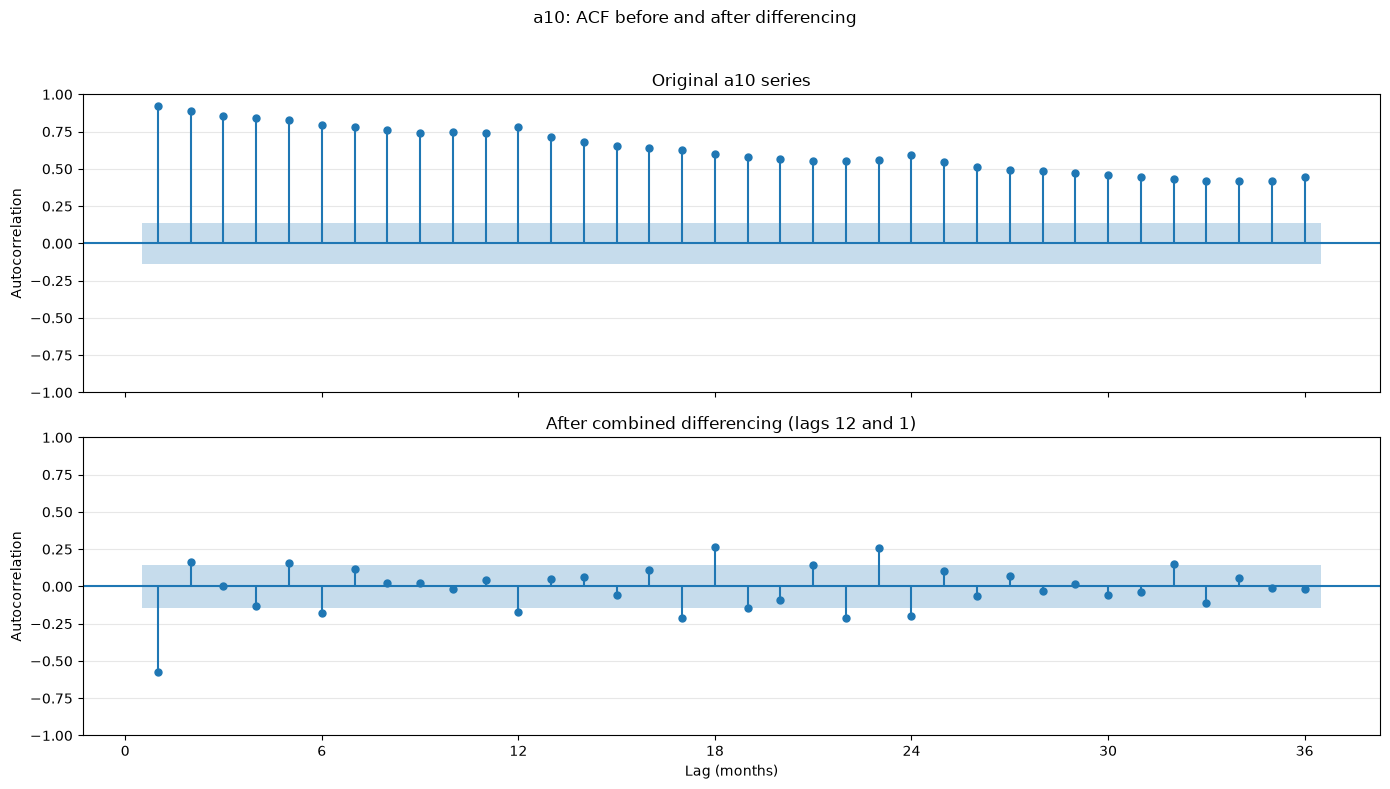

In [14]:
# TODO: Vykreslite ACF pôvodného radu a10 a ACF po vhodnej diferencii. 
# Pridajte do funkcie plot_acf parameter bartlett_confint=False pre vykreslenie fixného konfidenčného pásma.

from statsmodels.graphics.tsaplots import plot_acf

import matplotlib.pyplot as plt

# Monthly observations: lags 12, 24, and 36 represent 1, 2, and 3 years.
a10_acf_original = data_a10["value"].sort_index().asfreq("MS")
if a10_acf_original.isna().any():
    raise ValueError("Handle missing monthly values before computing ACF.")

# Exercise 6 supports combined differencing as a candidate for a10.
a10_acf_differenced = a10_acf_original.diff(12).diff(1).dropna()
acf_lags = 36
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)

for ax, series, title in zip(
    axes,
    (a10_acf_original, a10_acf_differenced),
    ("Original a10 series", "After combined differencing (lags 12 and 1)"),
):
    plot_acf(
        series, ax=ax, lags=acf_lags, alpha=0.05,
        bartlett_confint=False, zero=False, title=title,
    )
    ax.set_ylabel("Autocorrelation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(range(0, acf_lags + 1, 6))
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xlabel("Lag (months)")
fig.suptitle("a10: ACF before and after differencing")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


### Exercise 7 — interpretation

- ACF measures the linear association between observations separated by a given lag. Here, lag 1 is one month and lag 12 is one year. Lag 0 is omitted because its autocorrelation is always 1.
- The original a10 series has strong positive autocorrelation that persists across many lags, consistent with its trend. Peaks at annual lags reflect its seasonal structure.
- After combined differencing, the slow positive decay is substantially reduced. Remaining spikes indicate that differencing has not removed all serial dependence; they do not by themselves imply nonstationarity.
- With `bartlett_confint=False` and `alpha=0.05`, each panel uses an approximate pointwise 95% white-noise reference band of plus or minus 1.96 / sqrt(N), constant across nonzero lags. The bands differ slightly between panels because differencing removes 13 observations.
- Spikes outside the band suggest remaining autocorrelation at those lags. These are approximate individual comparisons, not a joint test across all 36 lags, and the original trending series does not satisfy the white-noise assumptions.
- A stationary series can still be autocorrelated. ADF rejection does not mean white noise, and remaining spikes are not a reason to keep differencing automatically.


## BONUS - 2 body

1. S datasetom a10 vykreslite 3 zložky časového radu pomocou STL (Seasonal and Trend decomposition using Loess). Keďže STL je aditívny, nezabudnite určiť, či dataset nepotrebuje logaritmickou transformáciu. Vyskúšajte STL bez logaritmickej transformácie. 

2. Aplikujte Box-Cox transformáciu. Aká je hodnota λ? Vysvetlite rozdiel medzi Box-Cox a diferenciou.

3. Otestujte dataset s KPSS testom. Vysvetli rozdiel medzi ADF a KPSS.


### Bonus 1 — STL with and without a logarithmic transformation

Compare the three components (trend, seasonal, and residual) on the original and natural-log scales. Both fits use the same settings and an annual seasonal period of 12 months.


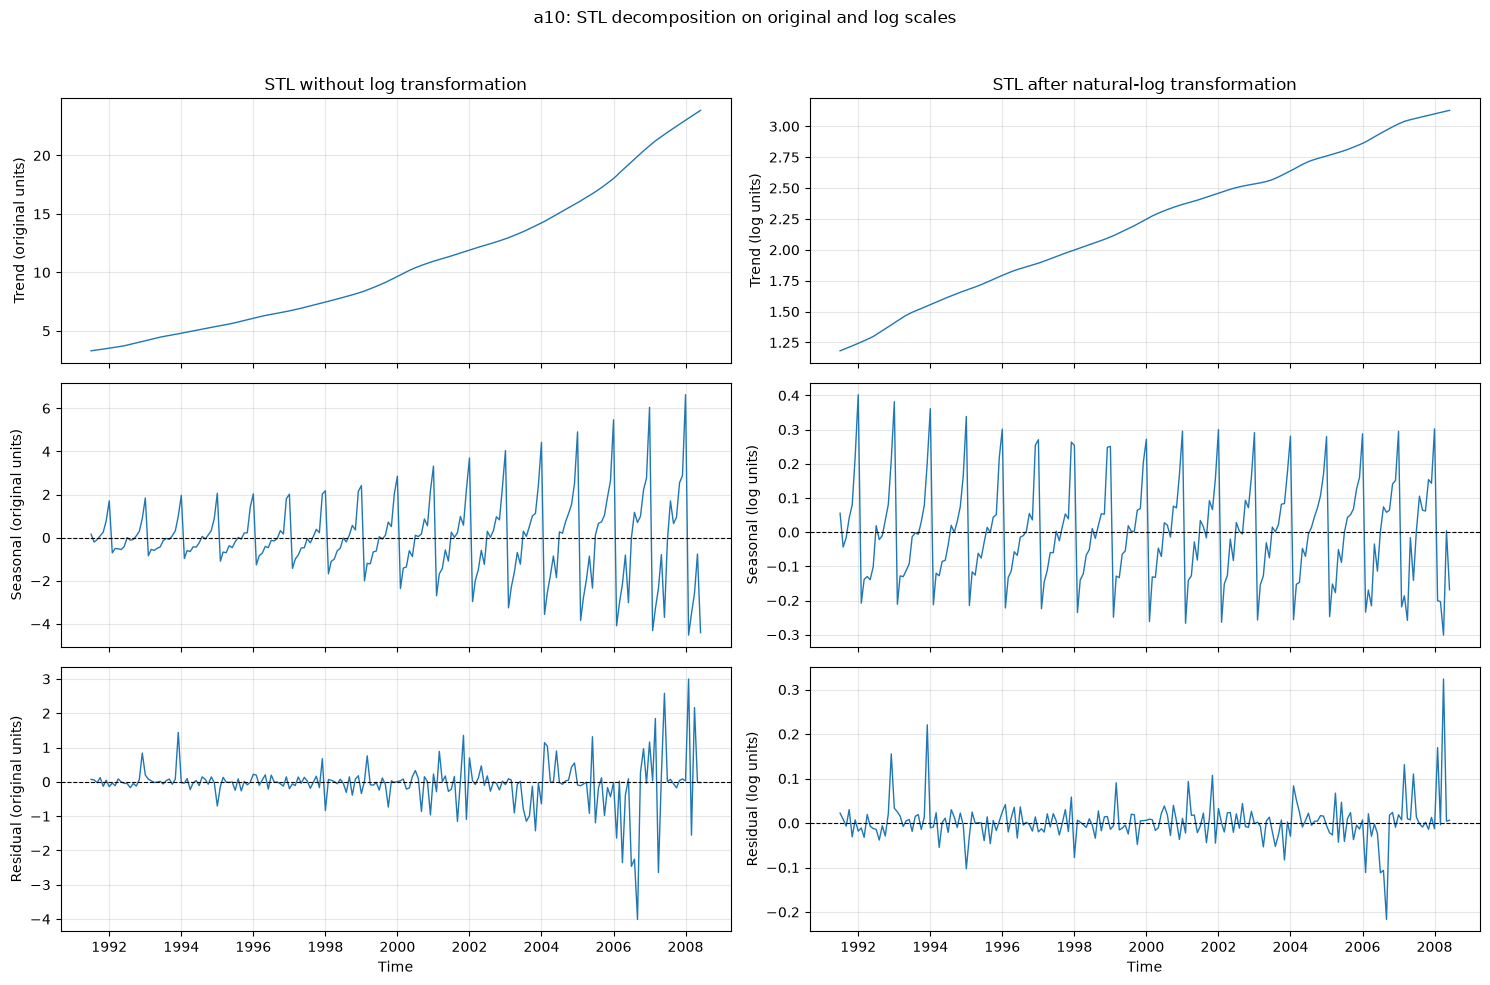

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# Use the original monthly observations, before any differencing.
a10_stl_series = data_a10["value"].sort_index().asfreq("MS")
if a10_stl_series.isna().any():
    raise ValueError("Handle missing monthly observations before STL.")
if (a10_stl_series <= 0).any():
    raise ValueError("The logarithmic transformation requires positive values.")

# STL is additive on the scale supplied to it.
# Robust fitting reduces the influence of outliers on trend and seasonality.
stl_raw = STL(a10_stl_series, period=12, robust=True).fit()
a10_log_series = np.log(a10_stl_series)
stl_log = STL(a10_log_series, period=12, robust=True).fit()

# Plot exactly three components for each version of the series.
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
for column, (result, title, units) in enumerate((
    (stl_raw, "STL without log transformation", "original units"),
    (stl_log, "STL after natural-log transformation", "log units"),
)):
    components = (result.trend, result.seasonal, result.resid)
    for row, (component, label) in enumerate(zip(
        components, ("Trend", "Seasonal", "Residual")
    )):
        ax = axes[row, column]
        ax.plot(component.index, component.values, linewidth=1)
        ax.set_ylabel(f"{label} ({units})")
        ax.grid(alpha=0.3)
        if row > 0:
            ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[0, column].set_title(title)
    axes[-1, column].set_xlabel("Time")

fig.suptitle("a10: STL decomposition on original and log scales")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


### Bonus 1 — interpretation

- **Without a log transformation:** STL separates a10 into an increasing trend, annual seasonality, and residuals, all in the original units. Seasonal fluctuations increase in absolute size as the level of the series grows.
- **With a log transformation:** Large values are compressed more strongly. The seasonal pattern is interpreted on a relative scale, making log-STL a useful choice for a10's growing seasonal amplitude. Inspect the seasonal and residual panels to assess how stable their fluctuations are over time.
- On the log scale, `log(y) = trend + seasonal + residual`. Exponentiating gives `y = exp(trend) * exp(seasonal) * exp(residual)`, a multiplicative representation on the original scale.
- STL can allow its seasonal pattern to change over time. Its additive form does not make logarithms mandatory; the transformation is motivated by the relationship between the series level and seasonal amplitude.
- The two columns have different units, so smaller numerical residuals on the log scale alone do not prove a better fit. Logarithms also do not remove the trend or guarantee stationarity.


### Bonus 2 — Box-Cox transformation

Estimate lambda by maximum likelihood on the original positive a10 values, apply the transformation, and compare the original and transformed time series.


Estimated Box-Cox lambda (maximum likelihood): 0.061506
Lambda = 0 corresponds to log(y); lambda = 1 corresponds to y - 1.


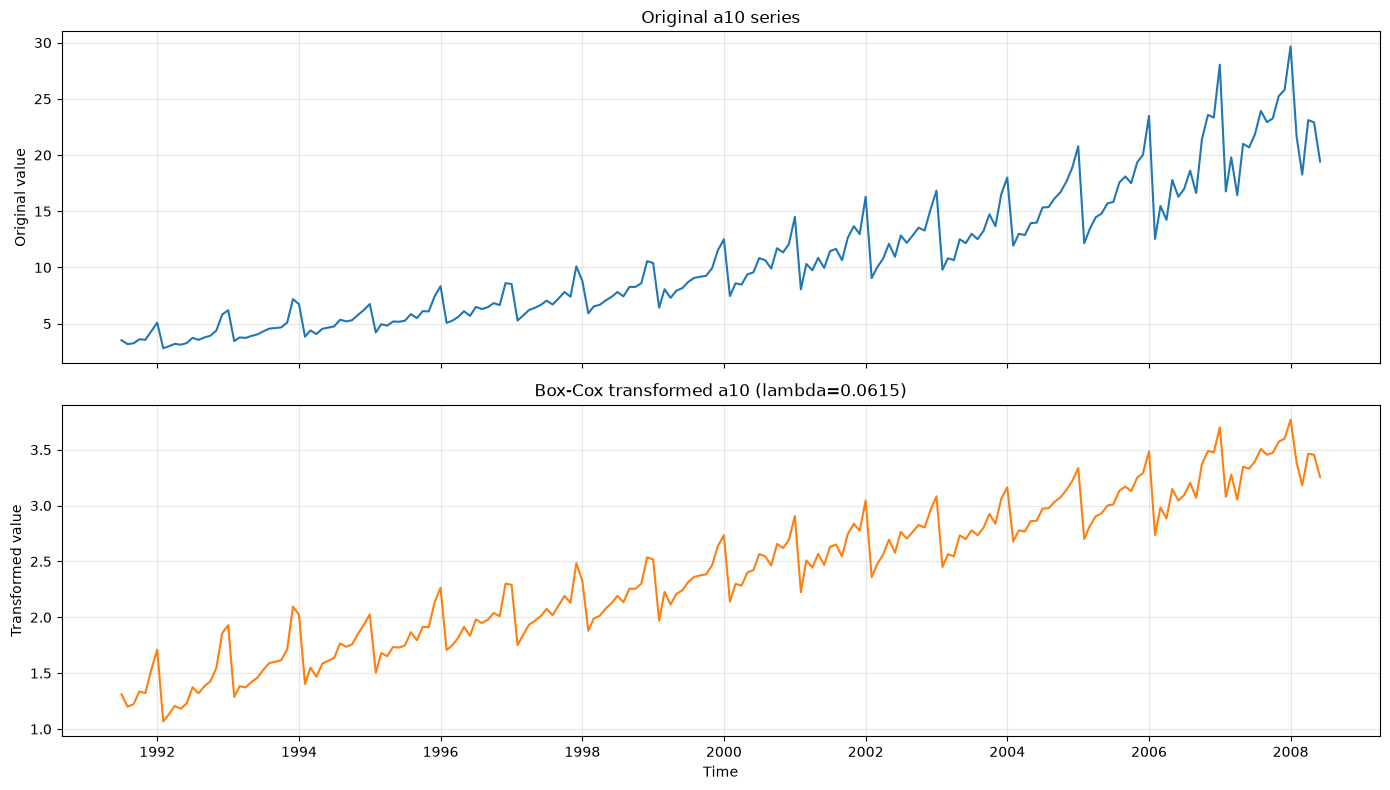

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox

# Apply Box-Cox to the original observations, before differencing.
a10_boxcox_original = data_a10["value"].sort_index().asfreq("MS")
if a10_boxcox_original.isna().any():
    raise ValueError("Handle missing monthly observations before Box-Cox.")
if (a10_boxcox_original <= 0).any():
    raise ValueError("Box-Cox requires strictly positive observations.")

# Without a supplied lambda, scipy estimates it by maximum likelihood.
boxcox_values, boxcox_lambda = boxcox(a10_boxcox_original.to_numpy())
a10_boxcox = pd.Series(
    boxcox_values, index=a10_boxcox_original.index, name="Box-Cox a10"
)
print(f"Estimated Box-Cox lambda (maximum likelihood): {boxcox_lambda:.6f}")
print("Lambda = 0 corresponds to log(y); lambda = 1 corresponds to y - 1.")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(a10_boxcox_original.index, a10_boxcox_original.values)
axes[0].set_title("Original a10 series")
axes[0].set_ylabel("Original value")
axes[1].plot(a10_boxcox.index, a10_boxcox.values, color="tab:orange")
axes[1].set_title(f"Box-Cox transformed a10 (lambda={boxcox_lambda:.4f})")
axes[1].set_ylabel("Transformed value")
axes[1].set_xlabel("Time")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Bonus 2 — interpretation

- Box-Cox transforms each positive observation separately: `(y**lambda - 1) / lambda` when lambda is nonzero, and `log(y)` when lambda is zero. The estimated value is printed above. Lambda depends on the estimation method and the observations used.
- For a10, a power below 1 compresses large values more strongly than small ones. This can reduce the growth of seasonal amplitude with the series level. It does not guarantee constant variance, remove the trend or seasonality, or establish stationarity.
- The original and transformed plots have different units. Compare how the amplitude changes over time within each plot rather than comparing their numerical ranges directly.

| Property | Box-Cox | Differencing |
| --- | --- | --- |
| Operation | Transforms each observation individually | Subtracts an earlier observation |
| Main purpose | Stabilize variance and change the scale | Reduce trend or seasonal persistence |
| Parameters | Power lambda | Lag, e.g. 1 or 12 |
| Observation count | Preserved for valid positive input | Initial values become undefined |
| Reversibility | Invertible given lambda | Reconstruction also requires initial values |

The operations can be combined: apply Box-Cox first, then difference the transformed series if needed. The lambda here is fitted directly to the levels by SciPy's likelihood criterion; it is not selected using a time-series residual model.


### Bonus 3 — KPSS and comparison with ADF

Test the original a10 series and its ordinary, seasonal, and combined differences. Use a 5% significance level and a constant in both tests. KPSS tests stationarity around a constant; ADF tests for a unit root.


In [3]:
import warnings
from inspect import signature
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

bonus3_alpha = 0.05
bonus3_adf_options = {"regression": "c", "autolag": "AIC"}
bonus3_kpss_options = {"regression": "c", "nlags": "auto"}
# Keep tuple results on versions supporting the newer result-object API.
for test, options in ((adfuller, bonus3_adf_options), (kpss, bonus3_kpss_options)):
    if "result_object" in signature(test).parameters:
        options["result_object"] = False

a10_kpss_original = data_a10["value"].sort_index().asfreq("MS")
if a10_kpss_original.isna().any():
    raise ValueError("Handle missing monthly observations before testing.")
bonus3_series = {
    "Original": a10_kpss_original,
    "Ordinary difference (1)": a10_kpss_original.diff(1),
    "Seasonal difference (12)": a10_kpss_original.diff(12),
    "Combined difference (12, 1)": a10_kpss_original.diff(12).diff(1),
}
joint_interpretations = {
    (True, False): "Supports level stationarity",
    (False, True): "Evidence against level stationarity",
    (False, False): "Inconclusive: neither null rejected",
    (True, True): "Conflicting evidence: both nulls rejected",
}

bonus3_rows = []
for label, series in bonus3_series.items():
    # Remove only the undefined initial values produced by differencing.
    values = series.dropna()
    # KPSS p-values outside the tabulated range are reported as bounds below.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        statistic, kpss_p, used_lags, critical = kpss(
            values, **bonus3_kpss_options
        )
    if kpss_p <= 0.01:
        kpss_p_label = "<=0.01"
    elif kpss_p >= 0.10:
        kpss_p_label = ">=0.10"
    else:
        kpss_p_label = f"{kpss_p:.6g}"

    adf_p = adfuller(values, **bonus3_adf_options)[1]
    reject_adf = adf_p < bonus3_alpha
    reject_kpss = kpss_p < bonus3_alpha
    bonus3_rows.append({
        "Transformation": label,
        "KPSS statistic": statistic,
        "KPSS p-value": kpss_p_label,
        "KPSS critical (5%)": critical["5%"],
        "KPSS lags": used_lags,
        "KPSS rejects stationarity": reject_kpss,
        "ADF p-value": adf_p,
        "ADF rejects unit root": reject_adf,
        "Joint interpretation": joint_interpretations[(reject_adf, reject_kpss)],
    })

kpss_comparison = pd.DataFrame(bonus3_rows).set_index("Transformation")
print("a10: ADF and KPSS comparison (alpha=0.05, regression='c').")
print(kpss_comparison.to_string(float_format=lambda value: f"{value:.6g}"))
print("KPSS boundary p-values are bounds, not exact values.")


a10: ADF and KPSS comparison (alpha=0.05, regression='c').
                             KPSS statistic KPSS p-value  KPSS critical (5%)  KPSS lags  KPSS rejects stationarity  ADF p-value  ADF rejects unit root                 Joint interpretation
Transformation                                                                                                                                                                             
Original                            2.01313       <=0.01               0.463          9                       True            1                  False  Evidence against level stationarity
Ordinary difference (1)            0.134106       >=0.10               0.463         45                      False     0.116653                  False  Inconclusive: neither null rejected
Seasonal difference (12)            1.17611       <=0.01               0.463          8                       True     0.247451                  False  Evidence against level stationarity
C

### Bonus 3 — interpretation

| Test | Null hypothesis with these settings | Meaning of p < 0.05 |
| --- | --- | --- |
| ADF | The series has a unit root | Reject the unit-root hypothesis |
| KPSS | The series is stationary around a constant | Reject level stationarity |

- **Original a10:** KPSS rejects level stationarity, while ADF does not reject a unit root. The tests give consistent evidence against level stationarity.
- **Ordinary difference:** Neither null hypothesis is rejected. This is inconclusive: failure to reject KPSS does not establish stationarity, and failure to reject ADF does not establish a unit root.
- **Seasonal difference:** KPSS rejects level stationarity and ADF does not reject a unit root. Seasonal differencing alone is insufficient under these settings.
- **Combined difference:** ADF rejects a unit root and KPSS does not reject level stationarity. Together, these results support this transformation as a candidate stationary series. They do not prove constant variance or white noise.
- KPSS uses `regression='c'` to test stationarity around a constant. With `regression='ct'`, it would instead test stationarity around a deterministic linear trend. This is a different null hypothesis.
- KPSS p-values are tabulated only from 0.01 to 0.10, so boundary results are displayed as bounds. Its automatic lag selection estimates the long-run variance; these lags are not the seasonal differencing period.
- Tests can have limited power and depend on their settings. Use them alongside plots and ACF, especially because a10's variance may change over time.
